# Seleção de regiões para novos poços de petróleo - Predição de reservas, análise de rentabilidade e avaliação de risco

# 1. Objetivo e Contexto de Negócio

A empresa fictícia de exploração de petróleo OilyGiant pretende investir no desenvolvimento de 200 novos poços de petróleo em uma entre três regiões disponíveis. Para apoiar essa decisão, a empresa disponibilizou três conjuntos de dados sintéticos, contendo aproximadamente 100.000 observações de potenciais localizações de poços por região, suas características geológicas e os respectivos volumes de reservas de petróleo.

O objetivo principal é identificar a região que oferece o maior lucro esperado, respeitando um limite de 2,5% para a probabilidade estimada de prejuízo.

Para isso, a empresa estabelece um cenário de exploração em que 500 localizações candidatas são avaliadas e as 200 com maior volume previsto de reservas são selecionadas para desenvolvimento. O investimento previsto é de US$ 100 milhões, com uma receita estimada de US$ 4,50 por barril de petróleo produzido.

## 1.1 Objetivo da Modelagem

Desenvolver um modelo de regressão linear para cada região, capaz de estimar o volume de reservas de petróleo de uma localização a partir de suas características disponíveis.

Essas previsões serão utilizadas para identificar os locais mais promissores para desenvolvimento. A eficácia dessa estratégia será avaliada utilizando dados de validação, nos quais os volumes reais de reservas são conhecidos.

Além da avaliação do desempenho preditivo, será realizada uma análise financeira para verificar se as escolhas realizadas com base nas previsões dos modelos resultariam em investimentos rentáveis.

## 1.2 Dados Disponíveis

São três conjuntos sintéticos de exploração geológica, cada um com 100.000 observações.  cada observação representa uma potencial localização para desenvolvimento de um poço de petróleo identificada pelo `id` (identificador do possível poço), características f0, f1, f2 (características geológicas sem descrição física) e product (volume das reservas, em milhares de barris).

Fontes: 
- geo_data_0.csv
- geo_data_1.csv
- geo_data_2.csv.

Colunas:
- `id` - identificador de cada localização para potencial poço de petróleo
- `f0`, `f1` e `f2` - características geológicas sem descrição física
- `product` - volume das reservas em **Milhares de Barris**



## 1.3 Premissas e Limitações do Cenário

- O número de "500 localizações a serem avaliadas" é uma premissa operacional estabelecida pela empresa. Os dados não permitem determinar por que essa quantidade foi escolhida, nem avaliar os custos de investigação de cada localização.

- Os dados utilizados são sintéticos e não incluem informações detalhadas sobre custos individuais de perfuração, condições operacionais, contratos ou fatores externos que poderiam afetar a rentabilidade.

Dessa forma, os resultados devem ser interpretados como uma avaliação da estratégia de seleção de poços sob as condições estabelecidas, e não como uma previsão definitiva do desempenho financeiro de uma operação real.

## 1.4 Estratégia

1. **Preparação dos dados:** avaliar a integridade dos conjuntos de dados e preparar as variáveis para modelagem.
2. **Treinamento e validação:** desenvolver um modelo de regressão linear para cada região, utilizando 75% das observações para treinamento e 25% para validação. Avaliar a precisão das previsões por meio da REQM.
3. **Análise preliminar de rentabilidade:** selecionar os 200 poços com maiores reservas previstas entre todas as observações de validação de cada região e calcular o lucro com base nas reservas reais. Essa análise permitirá comparar uma seleção específica de poços, sem representar integralmente o cenário operacional estabelecido.
4. **Simulação da estratégia de seleção:** utilizar bootstrapping para simular 1.000 conjuntos de 500 localizações candidatas por região, selecionando em cada um os 200 poços com maiores reservas previstas pelos respectivos modelos.
5. **Avaliação financeira:** calcular a distribuição dos lucros simulados, o lucro médio, sua variabilidade e a probabilidade estimada de prejuízo de cada região.
6. **Recomendação:** identificar a região com o maior lucro médio estimado entre aquelas que atendem ao limite de risco de 2,5%, considerando a utilização dos modelos treinados para futuras seleções de poços.

### Condições da OilyGiant:

- Apenas modelos de regressão linear serão aceitos.
- Ao explorar a região, um estudo de 500 pontos é realizado e os melhores 200 pontos são selecionados para calcular o lucro.
- O orçamento para o desenvolvimento de 200 poços de petróleo é 100 milhões de dólares.
- Um barril de petróleo bruto traz 4.5 dólares de receita. A receita de uma unidade de produto é 4.500 dólares (o volume de reservas está em milhares de barris).
- O risco de perdas máximo aceito é 2.5%.
- A métrica para escolher uma região será o Lucro Potencial Médio mais alto.

Os dados são sintéticos e não incluem nenhum detalhe de contratos ou características de poços.

## 1.5 Métricas de Avaliação

|Métrica | Propósito |
|---|---|
| REQM (mil barris)| Avaliar a qualidade das predições |
| Volume médio de reservas (mil barris) | Resumir o potencial de cada região |
| Lucro médio simulado (US$) | Comparar o desempenho financeiro de cada região dentro da simulação |
| Faixa central de 95% dos lucros simulados | Descrever a variabilidade nos cenários possíveis dentro da simulação |
| Probabilidade estimada de prejuízo (%) | Avaliar o risco de investimento em cada região |
| Erro padrão Monte Carlo (p.p.) | Quantificar incerteza atribuída a simulação da probabilidade estimada de prejuízo |

# 2. Exploração e Preparação dos Dados


O notebook procura os CSVs na pasta `data/` ou `datasets/` do repositório e, como alternativa, em `/datasets/` (que é usada no ambiente original). O diretório selecionado deve conter os três arquivos.

In [35]:
# Importando bibliotecas
from pathlib import Path

import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

from matplotlib import pyplot as plt

from IPython.display import display


In [36]:
filenames = [f"geo_data_{i}.csv" for i in range(3)]

# Carregando dados
data_dir = next(
    (
        path for path in [Path("../data"), Path("../datasets"), Path("/datasets/")] if all((path /
        filename).is_file() for filename in filenames)
    ),
    None,
)

if data_dir is None:
    raise FileNotFoundError("Os arquivos não foram encontrados. Coloque geo_data_0.csv, geo_data_1.csv e geo_data_2.csv em ../data/, ../datasets/ ou /datasets/.")


geo_data_0 = pd.read_csv(data_dir / "geo_data_0.csv")
geo_data_1 = pd.read_csv(data_dir / "geo_data_1.csv")
geo_data_2 = pd.read_csv(data_dir / "geo_data_2.csv")
region_datasets = {0: geo_data_0, 1: geo_data_1, 2: geo_data_2}

In [37]:
data_quality = pd.DataFrame(
    [
        {
            "Região": f"Região {region}",
            "Observações": len(df),
            "Valores ausentes": int(df.isna().sum().sum()),
            "Linhas duplicadas": int(df.duplicated().sum()),
            "IDs repetidos": int(df["id"].duplicated().sum()),
            "Reserva média (mil barris)": df["product"].mean(),
        }
        for region, df in region_datasets.items()
    ]
)
print("Qualidade dos dados por região:")
display(data_quality.round(2))

Qualidade dos dados por região:


,Região,Observações,Valores ausentes,Linhas duplicadas,IDs repetidos,Reserva média (mil barris)
0,Região 0,100000,0,0,10,92.50
1,Região 1,100000,0,0,4,68.83
2,Região 2,100000,0,0,4,95.00


In [38]:
for region, df in region_datasets.items():
    print(f"\nIDs Duplicados da Região {region}:")
    print(df.loc[df["id"].duplicated(keep=False)].sort_values(by="id"))


IDs Duplicados da Região 0:
          id        f0        f1         f2     product
66136  74z30  1.084962 -0.312358   6.990771  127.643327
64022  74z30  0.741456  0.459229   5.153109  140.771492
51970  A5aEY -0.180335  0.935548  -2.094773   33.020205
3389   A5aEY -0.039949  0.156872   0.209861   89.249364
69163  AGS9W -0.933795  0.116194  -3.655896   19.230453
42529  AGS9W  1.454747 -0.479651   0.683380  126.370504
931    HZww2  0.755284  0.368511   1.863211   30.681774
7530   HZww2  1.061194 -0.373969  10.430210  158.828695
63593  QcMuo  0.635635 -0.473422   0.862670   64.578675
1949   QcMuo  0.506563 -0.323775  -2.215583   75.496502
75715  Tdehs  0.112079  0.430296   3.218993   60.964018
21426  Tdehs  0.829407  0.298807  -0.049563   96.035308
92341  TtcGQ  0.110711  1.022689   0.911381  101.318008
60140  TtcGQ  0.569276 -0.104876   6.440215   85.350186
89582  bsk9y  0.398908 -0.400253  10.122376  163.433078
97785  bsk9y  0.378429  0.005837   0.160827  160.637302
41724  bxg6G -0.823

**Diagnóstico.** Não há valores ausentes ou linhas inteiramente duplicadas. Há, no entanto, **10 IDs repetidos na Região 0 e 4 em cada uma das Regiões 1 e 2**. As observações associadas a esses IDs apresentam características diferentes; por isso, foram preservadas. Em uma aplicação real, seria necessário verificar com a fonte dos dados se representam poços distintos ou erros de identificação. Para esta análise, as observações com identificadores repetidos serão mantidas e tratadas como registros distintos, uma vez que apresentam características diferentes. A origem dessas duplicações não pode ser determinada com os dados disponíveis.

O identificador `id` não será usado como variável preditora. A correspondência entre observações reais e previstas será preservada pelo **índice da linha**.

# 3. Treinando e Testando um modelo LinearRegression da Scikit-Learn para cada Região

Cada região recebe um modelo de **regressão linear** próprio. Os dados são divididos aleatoriamente em **75% para treinamento e 25% para validação**, com semente fixa para reprodução dos resultados.

A transformação com `StandardScaler` ocorre dentro de uma `Pipeline`: o ajuste dos parâmetros de escala acontece **apenas no treinamento**, evitando vazamento de informações da validação. Embora a padronização não seja necessária para regressão linear comum, ela demonstra uma estrutura segura e reutilizável de pré-processamento.

A métrica de avaliação é a **raiz do erro quadrático médio (REQM / RMSE)**, medida na mesma unidade da variável-alvo: milhares de barris.

## Ferramentas

In [39]:
def features_target_split(
    data_df: pd.DataFrame, non_training_columns: list[str], target_column: str
) -> tuple[pd.DataFrame, pd.Series]:
    """Separa características e variável alvo de um DataFrame."""
    features = data_df.drop(columns=non_training_columns + [target_column], axis=1)
    target = data_df.loc[:, target_column]
    return features, target


def model_pipe(num_columns: list[str]):
    ''' Cria um pipeline de pré-processamento e modelo de regressão linear.'''

    scaler = StandardScaler()

    preprocessor = ColumnTransformer(
        transformers=[("num_preprocess", scaler, num_columns)],
        remainder="passthrough"
    )

    pipe = Pipeline([
        ("column_transform", preprocessor),
        ("model", LinearRegression())
    ])

    return pipe



def region_workflow(
    data_df: pd.DataFrame,
    non_training_columns: list[str],
    feature_columns: list[str],
    target_column: str,
    test_size: float,
    random_state: int,
) -> tuple[pd.Series, pd.Series, pd.DataFrame, float, float, Pipeline]:
    """Treina e valida um modelo, preservando índices e IDs das previsões."""

    features, target = features_target_split(
        data_df, non_training_columns, target_column
    )

    features_train, features_valid, target_train, target_valid = train_test_split(
        features, target, test_size=test_size, random_state=random_state
    )

    pipe = model_pipe(feature_columns)
    pipe.fit(features_train, target_train)

    predicted_valid = pd.Series(pipe.predict(features_valid), index=target_valid.index)

    validation_results = pd.DataFrame(
        {"actual_product": target_valid,
         "predicted_product": predicted_valid}
        ).merge(
            data_df[non_training_columns],
            how="left",
            left_index=True,
            right_index=True
        )

    mean_predicted = predicted_valid.mean()
    root_mean_square_error = mean_squared_error(target_valid, predicted_valid) ** (1/2)

    return (
        target_valid,
        predicted_valid,
        validation_results,
        mean_predicted,
        root_mean_square_error,
        pipe,
    )

## Treinamento e Validação

In [40]:
# Variáveis para controle das funções
split_state = 12345 # random_state para train_test_split
valid_size = 0.25
non_training_columns = ["id"]
feature_columns = ["f0","f1","f2"]
target_column = "product"

# Região 0
(
    target_valid_0, predicted_valid_0, validation_results_0,
    mean_predicted_0, rmse_0, pipe_0,
) = region_workflow(
    geo_data_0, non_training_columns, feature_columns,
    target_column, valid_size, split_state,
)

# Região 1
(
    target_valid_1, predicted_valid_1, validation_results_1,
    mean_predicted_1, rmse_1, pipe_1,
) = region_workflow(
    geo_data_1, non_training_columns, feature_columns,
    target_column, valid_size, split_state,
)

# Região 2
(
    target_valid_2, predicted_valid_2, validation_results_2,
    mean_predicted_2, rmse_2, pipe_2,
) = region_workflow(
    geo_data_2, non_training_columns, feature_columns,
    target_column, valid_size, split_state,
)

# Resultados de validação por região
validation_by_region = {
    0: validation_results_0,
    1: validation_results_1,
    2: validation_results_2,
}

In [41]:
model_summary = pd.DataFrame(
    {
        "Região": ["Região 0", "Região 1", "Região 2"],
        "Reserva média prevista (mil barris)": [
            mean_predicted_0, mean_predicted_1, mean_predicted_2
        ],
        "REQM no Conjunto de Validação (mil barris)": [rmse_0, rmse_1, rmse_2],
    }
)
display(model_summary.round(2))

,Região,Reserva média prevista (mil barris),REQM no Conjunto de Validação (mil barris)
0,Região 0,92.59,37.58
1,Região 1,68.73,0.89
2,Região 2,94.97,40.03


## **Interpretação** 

As regiões 0 e 2 têm maiores reservas médias previstas, mas apresentam erros de previsão substancialmente maiores. A Região 1 tem a menor reserva média prevista (**68,73 mil barris**) e o menor REQM (**0,89 mil barris**). Isso indica melhor ajuste de previsão no conjunto de validação, **não necessariamente uma garantia de desempenho futuro**.

Essas métricas isoladamente não resolvem o problema de negócio: é necessário selecionar os poços com maiores previsões e medir os efeitos dessa seleção sobre lucro e risco. De qualquer forma, essa análise confirma que selecionar as regiões e pontos para desenvolvimento requer análise cuidadosa principalmente devido a limitação de estudo de 500 pontos e desenvolvimento de apenas 200 pontos.

# 4. Análise Exploratória de Rentabilidade

## 4.1 Premissas econômicas e ponto de equilíbrio

A receita estimada depende do volume de reservas efetivamente encontrado nos poços escolhidos. O lucro é dado por:

$\text{Lucro} = (\text{Reservas reais em mil barris} \times 4.500) - 100.000.000$

In [42]:
# Número de poços de Petróleo para desenvolvimento
oil_well_num = 200
# Orçamento de 100 milhões de dólares ($100.000.000) para o desenvolvimento
budget = 100_000_000
# Receita de uma unidade de produto (que equivalem a 1.000 barris de petróleo).
product_unit_rev = 4500
# Risco de perdas máximo em porcentagem. Manter apenas as regiões com risco inferior.
loss_risk_max = 0.025


# Dado o investimento de 100 milhões para 200 poços de petróleo, cada um precisa
# produzir, em média, uma quantidade de unidades equivalente a pelo menos 500 mil
# dólares para evitar prejuízos (isso é aproximadamente 111,1 unidades).
product_mean_min = budget / oil_well_num / product_unit_rev
print(f"Ponto de equilíbrio por poço: {product_mean_min:.2f} mil barris")

Ponto de equilíbrio por poço: 111.11 mil barris



Para recuperar US$ 100 milhões com 200 poços, seria necessário produzir em média **111,11 mil barris por poço**, sob as premissas simplificadas de preço e custo do projeto.

In [43]:
display(
    data_quality[["Região", "Reserva média (mil barris)"]].round(2)
)

,Região,Reserva média (mil barris)
0,Região 0,92.50
1,Região 1,68.83
2,Região 2,95.00


Nenhuma das três regiões apresenta um volume médio real de barris de petróleo que supere o volume médio mínimo para evitarmos prejuízos. Isso não significa que nenhuma região tenha potencial de gerar lucros. Nossa tarefa é ser seletivos ao escolher os pontos para possível desenvolvimento de poços de petróleo. Nenhuma das regiões se mostrou ideal em média de volume de barris de petróleo, tanto em dados reais quanto nos dados previstos pelos modelos.

# 5. Análise Preliminar de Rentabilidade dos 200 Poços Selecionados

Em cada região, classificamos as observações do conjunto de validação pelas **reservas previstas** e selecionamos as 200 maiores. O lucro dessa seleção é calculado com as **reservas reais** correspondentes, simulando a comparação posterior entre decisão e resultado observado.

Definindo o problema:
- Para cada região:
  - Top 200 poços em volumes previstos pelos modelos
  - Desses 200 poços, somar o volume __real__ com base nos dados verdadeiros
  - Calcular a receita com base no valor acima
  - Calcular o lucro potencial

Como essa seleção é realizada entre aproximadamente 25.000 observações de validação, esta análise considera um número de candidatos muito superior aos 500 previstos no cenário operacional. Seus resultados permitem avaliar uma seleção específica, mas não representam o lucro esperado da estratégia de exploração estabelecida pela empresa.

### Ferramentas

Função para selecionar os top 200 poços de petróleo, somar a receita com base no volume verdadeiro e calcular o lucro.
Retorna um DataFrame com os top 200 poços, a receita potencial e o lucro potencial calculado

In [44]:
def region_predicted_revenue_profit(
    region_data: pd.DataFrame,
    sort_column: str,
    target_column: str,
    count: int,
    budget: int,
    product_unit_rev,
) -> tuple[pd.DataFrame, float, float]:
    """Seleciona os poços por previsão e calcula a receita e lucro pelos valores reais."""

    top_wells = region_data.sort_values(
        by=sort_column,
        ascending=False
        ).head(count)

    target_product_sum = top_wells[target_column].sum()

    potential_revenue = target_product_sum * product_unit_rev

    profit = potential_revenue - budget

    return top_wells, potential_revenue, profit


In [45]:
top_wells_0, potential_revenue_0, profit_0 = region_predicted_revenue_profit(
    validation_results_0,
    "predicted_product",
    "actual_product",
    oil_well_num,
    budget,
    product_unit_rev,
)
top_wells_1, potential_revenue_1, profit_1 = region_predicted_revenue_profit(
    validation_results_1,
    "predicted_product",
    "actual_product",
    oil_well_num,
    budget,
    product_unit_rev,
)
top_wells_2, potential_revenue_2, profit_2 = region_predicted_revenue_profit(
    validation_results_2,
    "predicted_product",
    "actual_product",
    oil_well_num,
    budget,
    product_unit_rev,
)

top_wells_summary = pd.DataFrame(
    {
        "Região": ["Região 0", "Região 1", "Região 2"],
        "Receita (US$ milhões)": [
            potential_revenue_0, potential_revenue_1, potential_revenue_2
        ],
        "Lucro (US$ milhões)": [profit_0, profit_1, profit_2],
    }
)
top_wells_summary.iloc[:, 1:] /= 1_000_000
display(top_wells_summary.round(2))

,Região,Receita (US$ milhões),Lucro (US$ milhões)
0,Região 0,133.21,33.21
1,Região 1,124.15,24.15
2,Região 2,127.10,27.10


**Resultado preliminar.** A Região 0 apresenta o maior lucro observado na seleção específica de 200 poços (**US$ 33,21 milhões**). Porém, esse valor depende de uma única seleção, feita a partir do conjunto de validação. Ele não quantifica a variabilidade de lucro se outro conjunto de 500 pontos fosse considerado.

Para comparar alternativas de investimento de maneira consistente com a restrição de risco, é preciso simular diferentes conjuntos de candidatos.

# 6. Simulação de Lucros e Riscos de Prejuízo: Bootstrapping

Para cada região, o procedimento de *bootstrapping* é:

1. Sortear **500 observações com reposição** entre os resultados de validação.
2. Selecionar as **200 maiores reservas previstas** nessa amostra.
3. Calcular a receita pelas reservas **reais** das 200 selecionadas e subtrair o orçamento.
4. Repetir o procedimento **1.000 vezes** para obter uma distribuição empírica de lucros.
5. Calcular lucro médio, quantis de 2,5% e 97,5% e fração de simulações com lucro negativo.

**Interpretação estatística:** 

- Os quantis delimitam a faixa central de 95% dos **cenários simulados de lucro**. Não devem ser confundidos automaticamente com um intervalo de confiança de 95% para a **média** do lucro. 
- A estimativa de risco é condicional aos dados, modelos e hipóteses da simulação. 
- A reamostragem com reposição representa a hipótese de que futuras localizações de poços poderão apresentar características e volumes de reservas semelhantes aos observados nos dados disponíveis. Dessa forma, a simulação busca estimar a rentabilidade e o risco da aplicação dos modelos treinados a novos conjuntos de candidatos, mantendo fixos os modelos e as premissas financeiras.

In [46]:
# Intervalo Central de 95% dos Lucros Simulados (2.5% para cada cauda da
# distribuição)
profit_quantiles = (0.025,0.975)

bootstrap_sample_size = 500
bootstrap_samples = 1000

## Ferramentas

In [47]:
def profit_distribution(
    region_data: pd.DataFrame,
    sort_column: str,
    target_column: str,
    bootstrap_samples: int,
    bootstrap_sample_size: int,
    top_well_num: int,
    profit_quantiles: tuple[float, float],
    budget: float,
    product_unit_rev: float,
    random_state: int = 12345
) -> tuple[float,float,float,float,pd.Series]:
    """Simula a distribuição de lucros mantendo o processo de seleção 500->200 poços e calcula o lucro médio, intervalo central de 95% dos lucros simulados e probabilidade de perda."""

    bootstrap_state = np.random.RandomState(random_state)
    profits = []

    for _ in range(bootstrap_samples):

        subsample = region_data.sample(
            n=bootstrap_sample_size, replace=True, random_state=bootstrap_state
        )

        sorted_subsample = subsample.sort_values(
            by=sort_column,
            ascending=False
        )

        top_subsample = sorted_subsample.head(top_well_num)
        total_revenue = top_subsample[target_column].sum() * product_unit_rev
        profits.append(total_revenue - budget)

    profits = pd.Series(profits)
    lower = profits.quantile(profit_quantiles[0])
    upper = profits.quantile(profit_quantiles[1])
    profit_mean = profits.mean()
    loss_proba = (profits < 0).mean()

    return profit_mean, lower, upper, loss_proba, profits


In [48]:
profit_mean_0, lower_0, upper_0, loss_proba_0, profits_0 = profit_distribution(
    validation_results_0, "predicted_product", "actual_product",
    bootstrap_samples, bootstrap_sample_size, oil_well_num,
    profit_quantiles, budget, product_unit_rev,
)
profit_mean_1, lower_1, upper_1, loss_proba_1, profits_1 = profit_distribution(
    validation_results_1, "predicted_product", "actual_product",
    bootstrap_samples, bootstrap_sample_size, oil_well_num,
    profit_quantiles, budget, product_unit_rev,
)
profit_mean_2, lower_2, upper_2, loss_proba_2, profits_2 = profit_distribution(
    validation_results_2, "predicted_product", "actual_product",
    bootstrap_samples, bootstrap_sample_size, oil_well_num,
    profit_quantiles, budget, product_unit_rev,
)

In [49]:
bootstrap_summary = pd.DataFrame(
    {
        "Região": ["Região 0", "Região 1", "Região 2"],
        "Lucro médio (US$ milhões)": [
            profit_mean_0, profit_mean_1, profit_mean_2
        ],
        "Limite inferior 2,5% (US$ milhões)": [lower_0, lower_1, lower_2],
        "Limite superior 97,5% (US$ milhões)": [upper_0, upper_1, upper_2],
        "Risco de prejuízo (%)": [
            100 * loss_proba_0, 100 * loss_proba_1, 100 * loss_proba_2
        ],
        "Aprovada no limite de risco": [
            "Sim" if risk < loss_risk_max else "Não"
            for risk in (loss_proba_0, loss_proba_1, loss_proba_2)
        ],
        "Erro Padrão Monte Carlo (p.p.)": [
        100 * np.sqrt(p * (1 - p) / len(profits))
        for p, profits in zip(
            [loss_proba_0, loss_proba_1, loss_proba_2],
            [profits_0, profits_1, profits_2]
        )
        ]
    }
)
bootstrap_summary.iloc[:, 1:4] /= 1_000_000
display(bootstrap_summary.round(4))

,Região,Lucro médio (US$ milhões),"Limite inferior 2,5% (US$ milhões)","Limite superior 97,5% (US$ milhões)",Risco de prejuízo (%),Aprovada no limite de risco,Erro Padrão Monte Carlo (p.p.)
0,Região 0,3.9616,-1.1122,9.0977,6.9,Não,0.8015
1,Região 1,4.5605,0.3382,8.5229,1.5,Sim,0.3844
2,Região 2,4.0440,-1.6335,9.5036,7.6,Não,0.8380


### Visualização da rentabilidade e do risco

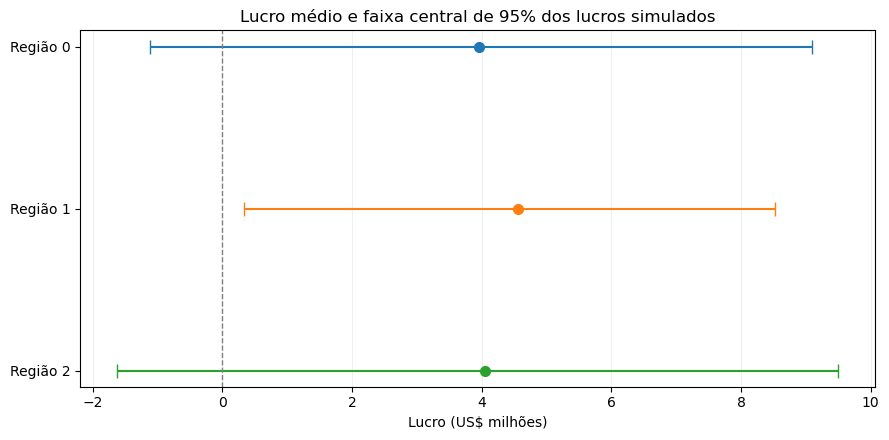

In [50]:
figures_dir = Path("../assets/figures/")
figures_dir.mkdir(exist_ok=True,parents=True)

fig, ax = plt.subplots(figsize=(9, 4.5))

for index, row in bootstrap_summary.iterrows():
    mean = row["Lucro médio (US$ milhões)"]
    lower = row["Limite inferior 2,5% (US$ milhões)"]
    upper = row["Limite superior 97,5% (US$ milhões)"]
    ax.errorbar(
        mean, index,
        xerr=[[mean - lower], [upper - mean]],
        fmt="o", capsize=5, markersize=7,
    )

ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_yticks(range(len(bootstrap_summary)))
ax.set_yticklabels(bootstrap_summary["Região"])
ax.invert_yaxis()
ax.set_xlabel("Lucro (US$ milhões)")
ax.set_title("Lucro médio e faixa central de 95% dos lucros simulados")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(figures_dir / "lucro_intervalos.png", dpi=160, bbox_inches="tight")
plt.show()

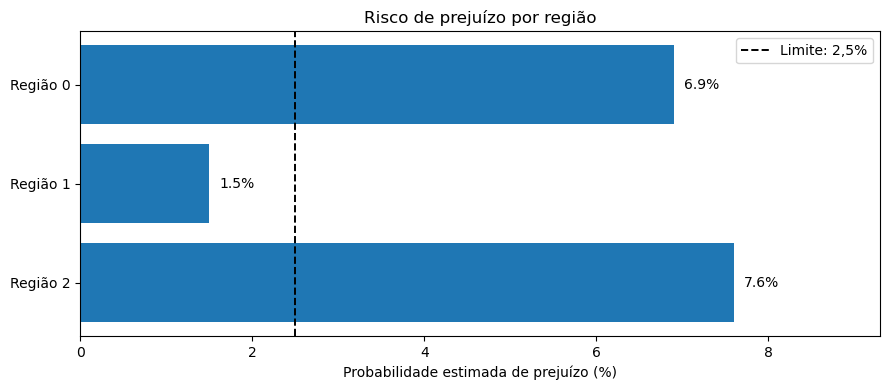

In [51]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(bootstrap_summary["Região"], bootstrap_summary["Risco de prejuízo (%)"])
ax.axvline(
    loss_risk_max * 100, color="black", linestyle="--", linewidth=1.4,
    label="Limite: 2,5%",
)
for i, risk in enumerate(bootstrap_summary["Risco de prejuízo (%)"]):
    ax.text(risk + 0.12, i, f"{risk:.1f}%", va="center")
ax.set_xlim(0, max(bootstrap_summary["Risco de prejuízo (%)"]) + 1.7)
ax.set_xlabel("Probabilidade estimada de prejuízo (%)")
ax.set_title("Risco de prejuízo por região")
ax.invert_yaxis()
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "risco_prejuizo.png", dpi=160, bbox_inches="tight")
plt.show()

O primeiro gráfico compara o lucro médio e a faixa central de 95% dos lucros simulados. O segundo destaca a restrição de **2,5%** de probabilidade de prejuízo. Os gráficos também são salvos na pasta `assets/figures/`

# 7. Conclusão e Recomendação

Foram desenvolvidos e validados três modelos de regressão linear, um para cada região, com o objetivo de estimar o volume de reservas de petróleo de potenciais poços e utilizar essas previsões para orientar decisões de desenvolvimento.

Na análise exploratória inicial, a Região 0 apresentou o maior lucro observado, de **US$ 33,21 milhões**, considerando os 200 poços com maiores reservas previstas entre aproximadamente 25.000 localizações disponíveis no conjunto de validação. Entretanto, essa seleção não representa o cenário operacional estabelecido pela OilyGiant, no qual apenas 500 localizações candidatas são avaliadas para a seleção de 200 poços.

Para avaliar a estratégia nas condições propostas, foi utilizada a técnica de *bootstrapping*, com 1.000 simulações por região. Em cada simulação, foram amostradas 500 observações com reposição, selecionando-se as 200 com maiores reservas previstas pelos respectivos modelos. Os lucros foram calculados com base nos volumes de reservas registrados no conjunto de dados.

## 7.1 Resultados da Análise

A simulação da estratégia de seleção apresentou os seguintes resultados:

| Região | Lucro médio simulado | Probabilidade estimada de prejuízo |
|---|---:|---:|
| Região 0 | US$ 3,96 milhões | 6,9% |
| **Região 1** | **US$ 4,56 milhões** | **1,5%** |
| Região 2 | US$ 4,04 milhões | 7,6% |

A Região 1 apresentou o maior lucro médio simulado e a menor probabilidade estimada de prejuízo. Também foi a única região a atender ao limite de risco inferior a 2,5% estabelecido pela OilyGiant.

Além disso, o modelo da Região 1 apresentou o melhor desempenho preditivo no conjunto de validação, com REQM de aproximadamente 0,89 mil barris, significativamente inferior aos resultados obtidos nas demais regiões.

## 7.2 Recomendação

**Recomenda-se a Região 1 para o desenvolvimento dos novos poços de petróleo, considerando a estratégia de seleção baseada nas previsões do modelo de regressão linear treinado para essa região.**

Essa recomendação considera a capacidade dos modelos de orientar decisões de desenvolvimento financeiramente favoráveis, e não apenas os volumes de reservas disponíveis em cada região.

Embora a Região 0 tenha produzido o maior lucro na análise exploratória inicial, esse resultado foi obtido por meio de uma seleção específica realizada entre aproximadamente 25.000 candidatos. Quando a estratégia foi avaliada em diferentes amostras de 500 candidatos, seu modelo apresentou maior risco estimado de prejuízo e menor lucro médio simulado do que o modelo da Região 1.

Portanto, a recomendação não significa necessariamente que a Região 1 possua as maiores reservas ou os poços individualmente mais rentáveis, mas que **a estratégia de seleção baseada em seu modelo apresentou a melhor combinação de rentabilidade média estimada e risco financeiro entre as alternativas avaliadas**.

## 7.3 Interpretação e Alcance da Recomendação

Os resultados indicam que a Região 1 é a alternativa mais favorável para a estratégia de investimento e seleção de poços avaliada neste projeto.

Essa conclusão depende da hipótese de que futuras localizações apresentem distribuições de características geológicas e volumes de reservas semelhantes às observadas nos dados disponíveis, bem como da manutenção das premissas financeiras utilizadas.

As probabilidades de prejuízo representam estimativas condicionadas aos dados sintéticos, aos modelos treinados e ao procedimento de reamostragem adotado. Portanto, não devem ser interpretadas como probabilidades exatas de prejuízo em operações reais.

O projeto demonstra, assim, a importância de avaliar modelos preditivos não apenas por sua precisão, mas também pelos resultados financeiros das decisões tomadas com base em suas previsões.

# 8. Limitações e Próximos Passos

- **Dados sintéticos e premissas fixas:** não há variação de preços, custos operacionais, contratos ou restrições físicas de desenvolvimento.
- **Generalização:** as estimativas dependem da representatividade das amostras e da permanência das relações entre características e reservas.
- **Amostragem com reposição:** uma simulação bootstrap pode conter a mesma observação mais de uma vez; isso representa uma técnica estatística de reamostragem, não um plano operacional literal de perfuração de 200 poços físicos distintos.
- **Probabilidades aproximadas:** o risco de prejuízo deriva de 1.000 simulações, portanto possui incerteza amostral e não deve ser interpretado como probabilidade exata.
- **Identificadores:** os IDs repetidos devem ser esclarecidos antes de uso em uma operação real.

Em uma implementação real, os próximos passos seriam validar a integridade dos identificadores, analisar preços e custos variáveis, testar a robustez do modelo em novos dados e revisar a estratégia de amostragem à luz das restrições operacionais.